In [1]:
# plot the accuracy improvement of one basin with iterations
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os, sys, glob, json

In [12]:
# define basin

tarbasin = 332
iternum = 7
tarexp = 'exp5'
outpath_parent = f"/glade/campaign/cgd/tss/people/guoqiang/HBV_CAMELS/LSE{tarexp}"
outpath_external_iter0 = "/glade/campaign/cgd/tss/people/guoqiang/HBV_CAMELS/LSEexp1"

subsetPath = f'/glade/campaign/cgd/tss/people/guoqiang/HBV_CAMELS/data_Yalan/Sub531ID.txt'
with open(subsetPath, 'r') as fp:
     camels_ids = json.load(fp)

tarID = camels_ids[tarbasin]

# load LSE metrics

df_lse_metric = []
for i in range(iternum):
    if i == 0:
        infile = f'{outpath_external_iter0}/{tarID}/outputs/iter{i}_all_metric.csv'    
    else:
        infile = f'{outpath_parent}/{tarID}/outputs/iter{i}_all_metric.csv'    
    dfi = pd.read_csv(infile)
    dfi['basin'] = tarbasin
    dfi['iter'] = i
    dfi['trial'] = np.arange(len(dfi))
    if len(df_lse_metric) == 0:
        df_lse_metric = dfi
    else:
        df_lse_metric = pd.concat([df_lse_metric, dfi])

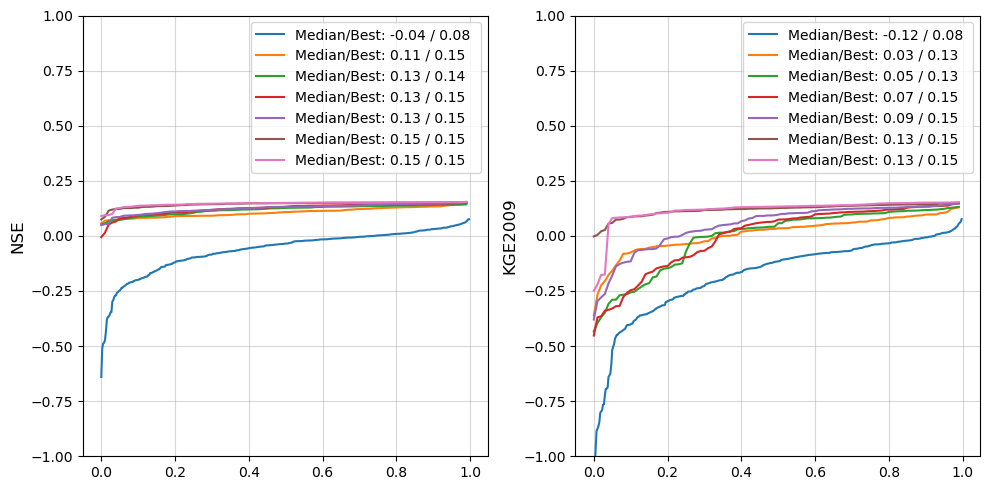

In [13]:
# plot cdf curves

metrics = ['nse', 'kge2009']
fig, axes = plt.subplots(1, 2, figsize=(10, 5), sharex=True)

for idx, metname in enumerate(metrics):

    for i in range(iternum):
        indi = df_lse_metric['iter'] == i   
        di = df_lse_metric[metname][df_lse_metric['iter'] == i].values
        di = np.sort(di)
        axes[idx].plot(np.arange(len(di))/len(di), di, label=f'Median/Best: {np.nanmedian(di):.2f} / {np.nanmax(di):.2f} ')
        axes[idx].set_ylabel(metname.upper(), fontsize=12)
        axes[idx].legend(loc='best', fontsize=10)
        axes[idx].grid(alpha=0.5)
        axes[idx].set_ylim(-1, 1)


plt.tight_layout()
plt.show()